# Multilayer RBNO

In [ ]:

num_samples = 1000 #Size of the dataset

## 1. Sample the input for poisson problem from GP and solve
The goal is to perform operator learning on the poisson equation (in 2d on [0,1]^2):
$$\Delta u = -f_{cv}$$
Where we consider $f_{cv}$ as the input and the solution function $u$ as output.

To create a dataset, we sample $f_{cv}$ from a Gaussian process and solve the equation numerically to get $u_{sol}$.
The Dataset consists of num_samples tuples $(X,Y) = (f_{cv},u_{sol})$.



In [156]:
from fipy import Grid2D, CellVariable, DiffusionTerm, numerix as np
import numpy as onp
import matplotlib.pyplot as plt
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
from typing import Tuple

import jax
import jax.numpy as jnp
from jaxtyping import Float, Array



key = jax.random.PRNGKey(356)  # <-- correct key ctor

In [ ]:
N = 100
L = 1.0
dx = L / N
mesh = Grid2D(nx=N, ny=N, dx=dx, dy=dx)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)
xc, yc = mesh.cellCenters

In [117]:

# --- stability: 64-bit helps Cholesky on larger grids ---
jax.config.update("jax_enable_x64", True)

@dataclass
class Gaussian:
    mu: Float[Array, "N"]
    Sigma: Float[Array, "N N"]
    jitter: float = 1e-6

    @cached_property
    def L(self) -> Float[Array, "N N"]:
        n = self.Sigma.shape[0]
        # enforce symmetry (tiny fp errors can hurt Cholesky)
        S = 0.5 * (self.Sigma + self.Sigma.T)
        return jnp.linalg.cholesky(S + self.jitter * jnp.eye(n, dtype=S.dtype))

    def sample(self, key: jax.random.KeyArray, num_samples: int = 1
               ) -> Float[Array, "num_samples N"]:
        n = self.mu.shape[0]
        z = jax.random.normal(key, shape=(num_samples, n), dtype=self.mu.dtype)
        return self.mu + z @ self.L.T


def rbf_kernel(
    X: Float[Array, "N 2"], Y: Float[Array, "M 2"],
    variance: float = 1.0, lengthscales: Tuple[float, float] = (0.2, 0.2),
    dtype=jnp.float64
) -> Float[Array, "N M"]:
    ℓx, ℓy = lengthscales
    Xs = X / jnp.array([ℓx, ℓy], dtype=dtype)
    Ys = Y / jnp.array([ℓx, ℓy], dtype=dtype)
    diff = Xs[:, None, :] - Ys[None, :, :]
    sqdist = jnp.sum(diff * diff, axis=-1)
    return jnp.asarray(variance, dtype=dtype) * jnp.exp(-0.5 * sqdist)


def sample_gp_on_grid(
    key: jax.random.KeyArray,
    nx: int = 80, ny: int = 80,
    xlim=(0.0, 1.0), ylim=(0.0, 1.0),
    variance: float = 1.0, lengthscales=(0.15, 0.25),
    jitter: float = 1e-5, num_samples: int = 1,
    dtype=jnp.float64
):
    xs = jnp.linspace(xlim[0], xlim[1], nx, dtype=dtype)
    ys = jnp.linspace(ylim[0], ylim[1], ny, dtype=dtype)
    Xg, Yg = jnp.meshgrid(xs, ys, indexing="xy")       # (ny, nx)
    XY = jnp.stack([Xg.ravel(), Yg.ravel()], axis=-1)  # (N,2), N=nx*ny

    K = rbf_kernel(XY, XY, variance=variance, lengthscales=lengthscales, dtype=dtype)
    mu = jnp.zeros(K.shape[0], dtype=dtype)
    gp = Gaussian(mu=mu, Sigma=K, jitter=jitter)

    key, sub = jax.random.split(key)
    samples_flat = gp.sample(sub, num_samples=num_samples)         # (S, N)
    samples_img = samples_flat.reshape(num_samples, ny, nx)        # (S, ny, nx)
    return samples_img, xs, ys

min: -5.116897584182346 max: 5.691821166396084 std: 2.0543847434261897 has_nan: False


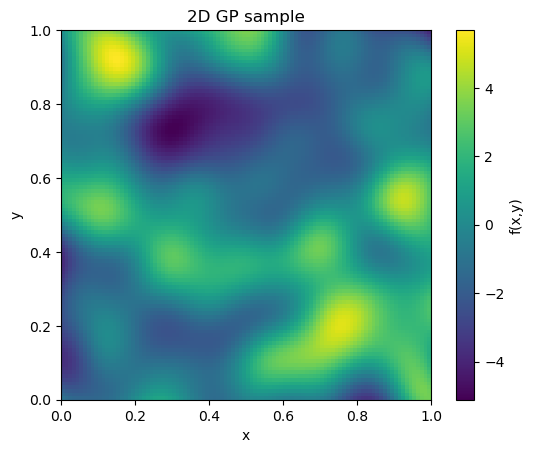

In [118]:
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=1
)
s0 = onp.array(samples[2])  # to NumPy for plotting
print("min:", onp.nanmin(s0), "max:", onp.nanmax(s0), "std:", onp.nanstd(s0),
          "has_nan:", onp.isnan(s0).any())

# simplest, robust visualization:
plt.figure()
plt.imshow(s0, origin="lower", extent=[float(xs[0]), float(xs[-1]), float(ys[0]), float(ys[-1])], aspect="equal")
plt.colorbar(label="f(x,y)")
plt.title("2D GP sample")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

In [119]:
#We sample f_cv from the gaussian process and solve the Poisson equation with -f_cv as RHS

num_samples = 1000
frac_train = 0.7
solution = np.zeros(shape=(num_samples,N,N))
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=num_samples
)
for i in range(len(samples)):
    s = onp.array(samples[i])  # to NumPy for plotting
    # s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
    s_flat = onp.asarray(s).ravel(order="C")              # length = N*N
    assert s_flat.size == mesh.numberOfCells

    f_cv = CellVariable(mesh=mesh, value=s_flat)

    u = CellVariable(name="u", mesh=mesh, value=0.0)
    u.constrain(0.0, where=mesh.exteriorFaces)
    eq = DiffusionTerm(var=u) == -f_cv
    eq.solve(var=u)
    u_grid = u.value.reshape((N, N), order="C")  # shape back to grid
    solution[i] = u_grid

In [122]:
X,Y = samples,solution

## 2. Offline PCA and calculation of reduced basis encoder and decoder
We first perform an offline PCA on snapshots of the input and outputs respectively.

In [197]:
num_snapshots = 500 # We take the first 100 samples and solutions of the dataset a snapshots 

In [198]:
#Normalize data
X, Y = onp.array(X),np.array(Y)
# Suppose X has shape (num_samples, N, N) or (num_samples, C, N, N)
x_mean = X.mean()
x_std  = X.std()

y_mean = Y.mean()
y_std  = Y.std()


Xn = (X - x_mean) / (x_std + 1e-6)
Yn = (Y - y_mean) / (y_std + 1e-6)

In [199]:

from sklearn.decomposition import PCA
from dataclasses import dataclass

@dataclass
class PCAConfig:
    svd_solver: str = "full"   # or "auto", "randomized" for very large D
    whiten: bool = False
    random_state: int = 0

class PCAReducer:
    """
    PCA-based reduced-basis helper for (num_samples, N, N) fields.
    - Fits separate PCA models for inputs and outputs.
    - Projects to first k components or components covering a variance cutoff j.
    - Reconstructs outputs from reduced coefficients.
    """
    def __init__(self, cfg: PCAConfig = PCAConfig()):
        self.cfg = cfg
        self.pca_in:  PCA | None = None
        self.pca_out: PCA | None = None
        self.shape_ = None  # (N, N)

    # apply PCA to input and outpus snapshots respectively
    def fit(self, samples: np.ndarray, solution: np.ndarray):
        """
        samples, solution: (num_samples, N, N).
        """
        assert samples.shape == solution.shape and samples.ndim == 3, "Use (num_samples, N, N)"
        num_samples, N, M = samples.shape
        self.shape_ = (N, M)

        X_in  = samples.reshape(num_samples, -1).astype(np.float32, copy=False)     #Flatten
        Y_out = solution.reshape(num_samples, -1).astype(np.float32, copy=False)    #Flatten

        self.pca_in  = PCA(n_components=None, svd_solver=self.cfg.svd_solver,
                           whiten=self.cfg.whiten, random_state=self.cfg.random_state).fit(X_in)
        self.pca_out = PCA(n_components=None, svd_solver=self.cfg.svd_solver,
                           whiten=self.cfg.whiten, random_state=self.cfg.random_state).fit(Y_out)
        return self

    # ---------- Utilities ----------
    @staticmethod
    def _k_from_cutoff(evr: np.ndarray, cutoff: float) -> int:
        # smallest k with cumulative explained variance ratio >= cutoff
        return int(np.searchsorted(np.cumsum(evr), cutoff) + 1)

    def k_from_cutoff(self, j_in: float = 0.99, j_out: float = 0.99) -> tuple[int, int]:
        """Return (k_in, k_out) meeting given variance cutoffs."""
        assert self.pca_in and self.pca_out
        k_in  = self._k_from_cutoff(self.pca_in.explained_variance_ratio_,  j_in)
        k_out = self._k_from_cutoff(self.pca_out.explained_variance_ratio_, j_out)
        return k_in, k_out

    # Mapping inputs and outputs to coefficients respectively
    def transform_inputs(self, samples: np.ndarray, k: int | None = None) -> np.ndarray:
        """Return input PCA coefficients (num_samples, k)."""
        assert self.pca_in
        X = samples.reshape(samples.shape[0], -1).astype(np.float32, copy=False)
        Z = self.pca_in.transform(X)
        return Z[:, :k] if k is not None else Z

    def transform_outputs(self, solution: np.ndarray, k: int | None = None) -> np.ndarray:
        """Return output PCA coefficients (num_samples, k)."""
        assert self.pca_out
        Y = solution.reshape(solution.shape[0], -1).astype(np.float32, copy=False)
        Z = self.pca_out.transform(Y)
        return Z[:, :k] if k is not None else Z

    # ---------- Inverse map for coefficients to output ----------
    def inverse_outputs(self, coeffs: np.ndarray, k: int | None = None) -> np.ndarray:
        """
        Reconstruct outputs (num_samples, N, N) from output PCA coeffs.
        If k is provided, only the first k components are used.
        """
        assert self.pca_out and self.shape_ is not None
        if k is None:
            # Full inverse using sklearn's inverse_transform
            Y_flat = self.pca_out.inverse_transform(coeffs)
        else:
            # Manual partial inverse: mean + coeffs @ components[:k]
            comps = self.pca_out.components_[:k, :]
            mean  = self.pca_out.mean_
            Y_flat = coeffs @ comps + mean
        return Y_flat.reshape((coeffs.shape[0], *self.shape_))

    # ---------- Plots ----------
    def plot_explained_variance(self):
        """Plot explained variance ratios for input and output PCA."""
        assert self.pca_in and self.pca_out
        fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
        axes[0].plot(self.pca_in.explained_variance_ratio_, marker='o', linewidth=1)
        axes[0].set_title("Input PCA — explained variance ratio")
        axes[0].set_xlabel("Component")
        axes[0].set_ylabel("EVR")
        axes[0].grid(True)
        axes[1].plot(self.pca_out.explained_variance_ratio_, marker='o', linewidth=1)
        axes[1].set_title("Output PCA — explained variance ratio")
        axes[1].set_xlabel("Component")
        axes[1].set_ylabel("EVR")
        axes[1].grid(True)
        plt.show()

    # ---------- Accessors ----------
    @property
    def input_components(self) -> np.ndarray:
        """(n_in_components, D) principal directions for inputs."""
        assert self.pca_in
        return self.pca_in.components_

    @property
    def output_components(self) -> np.ndarray:
        """(n_out_components, D) principal directions for outputs."""
        assert self.pca_out
        return self.pca_out.components_


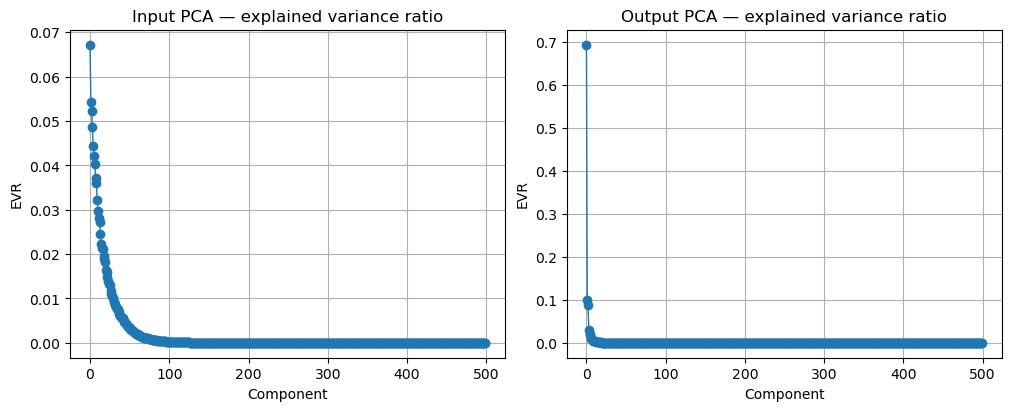

k_in:  100 k_out:  93


In [205]:

# Fit on snapshot sets
rb = PCAReducer().fit(Xn[:num_snapshots], Yn[:num_snapshots])

# Inspect spectra
rb.plot_explained_variance()

# Pick dimensions by cutoff (e.g., 99% variance)
epsilon = 1e-5
k_in, k_out = rb.k_from_cutoff(j_in=1-500*epsilon, j_out=1-epsilon)
print("k_in: ",k_in,"k_out: ", k_out)



## 3. Architecture of multilayer reduced basis NO

In [206]:
# fno2d_train.py
from __future__ import annotations
import math
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn import BatchNorm2d
torch.set_default_dtype(torch.float32)

### Reduced Basis Resnet
This is one layer of the multilayer RBNO:
The input is mapped to its coefficients of the reduced basis. Then follows a Resnet on the coefficients,  which are the mapped back.
Basically:

z_in = encode(x)                    # (B, k_in)

h = F.gelu(in_lin(z_in))

h = ResNet(h)                       #Resnet of depth

z_out = out_lin(h)                  # (B, k_out)

y = self.decode(z_out)              # (B, D)

return y

In [207]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(self, d_model: int, dropout: float = 0.0):
        super().__init__()
        self.lin1 = nn.Linear(d_model, d_model)
        self.lin2 = nn.Linear(d_model, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.act = nn.GELU()
    def forward(self, x):
        y = self.lin2(self.act(self.lin1(self.norm(x))))
        y = self.dropout(y)
        return x + y

class ReducedBasisResNet(nn.Module):
    """
    Encodes (B,N,N) -> k_in coeffs via PCA_in,
    ResNet in coefficient space,
    Decodes k_out coeffs -> (B,1,N,N) via PCA_out.
    """
    def __init__(self, rb, k_in: int, k_out: int, hidden: int = 256, depth: int = 4, dropout: float = 0.0):
        super().__init__()
        # --- sanity checks on PCA ---
        if getattr(rb, "pca_in", None) is None or getattr(rb, "pca_out", None) is None:
            raise ValueError("PCAReducer must be fitted: call rb.fit(samples, solution) before constructing the model.")
        if getattr(rb, "shape_", None) is None:
            raise ValueError("PCAReducer.shape_ is None; did you fit it on (num_samples, N, N) arrays?")
        self.N, self.M = rb.shape_
        D = self.N * self.M

        ncomp_in  = int(getattr(rb.pca_in,  "n_components_", rb.pca_in.components_.shape[0]))
        ncomp_out = int(getattr(rb.pca_out, "n_components_", rb.pca_out.components_.shape[0]))
        if not (1 <= k_in <= ncomp_in):
            raise ValueError(f"k_in={k_in} out of range (1..{ncomp_in}).")
        if not (1 <= k_out <= ncomp_out):
            raise ValueError(f"k_out={k_out} out of range (1..{ncomp_out}).")

        comps_in  = rb.pca_in.components_[:k_in, :].astype(np.float32)
        mean_in   = rb.pca_in.mean_.astype(np.float32)
        comps_out = rb.pca_out.components_[:k_out, :].astype(np.float32)
        mean_out  = rb.pca_out.mean_.astype(np.float32)

        if comps_in.shape[1] != D or comps_out.shape[1] != D or mean_in.shape[0] != D or mean_out.shape[0] != D:
            raise ValueError(
                f"PCA basis size mismatch: expected D={D} from (N,M)=({self.N},{self.M}); "
                f"got comps_in:{comps_in.shape}, comps_out:{comps_out.shape}, "
                f"mean_in:{mean_in.shape}, mean_out:{mean_out.shape}"
            )

        # register buffers (move with .to(device), no grads)
        self.register_buffer("enc_components_t", torch.from_numpy(comps_in))  # (k_in, D)
        self.register_buffer("enc_mean",        torch.from_numpy(mean_in))    # (D,)
        self.register_buffer("dec_components",  torch.from_numpy(comps_out))  # (k_out, D)
        self.register_buffer("dec_mean",        torch.from_numpy(mean_out))   # (D,)

        self.k_in, self.k_out, self.D = comps_in.shape[0], comps_out.shape[0], D

        # ResNet head
        self.in_lin  = nn.Linear(self.k_in, hidden)
        self.blocks  = nn.Sequential(*[ResidualBlock(hidden, dropout=dropout) for _ in range(depth)])
        self.out_lin = nn.Linear(hidden, self.k_out)

    def encode(self, x_flat: torch.Tensor) -> torch.Tensor:
        if x_flat.shape[-1] != self.D:
            raise RuntimeError(f"encode expects (...,{self.D}), got {tuple(x_flat.shape)}")
        x_flat = x_flat.to(dtype=torch.float32)
        x_c = x_flat - self.enc_mean[None, :]
        return x_c @ self.enc_components_t.T

    def decode(self, z_out: torch.Tensor) -> torch.Tensor:
        if z_out.shape[-1] != self.k_out:
            raise RuntimeError(f"decode expects (...,{self.k_out}), got {tuple(z_out.shape)}")
        z_out = z_out.to(dtype=torch.float32)
        return z_out @ self.dec_components + self.dec_mean[None, :]

    def forward(self, x):
        # Accept (B,N,N) or (B,1,N,N)
        if x.ndim == 4 and x.shape[1] == 1:
            x = x[:, 0, :, :]
        if not (x.ndim == 3 and x.shape[1] == self.N and x.shape[2] == self.M):
            raise RuntimeError(f"Expected x as (B,{self.N},{self.M}) or (B,1,{self.N},{self.M}); got {tuple(x.shape)}")

        B = x.shape[0]
        x_flat = x.reshape(B, self.D).to(x.device, dtype=torch.float32)

        z_in = self.encode(x_flat)               # (B, k_in)

        h = F.gelu(self.in_lin(z_in))
        h = self.blocks(h)                       #Resnet of depth
        z_out = self.out_lin(h)                  # (B, k_out)

        y_flat = self.decode(z_out)              # (B, D)
        y = y_flat.reshape(B, 1, self.N, self.M)
        return y
    

### Multilayer RBNet
Now we stack multiple RB Resnet layers ontop of each other, together with a residual connection.

In [208]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from typing import Optional

class ScalarGate(nn.Module):
    """Learnable scalar multiplier for residual connection."""
    def __init__(self, init: float = 0.1):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(float(init), dtype=torch.float32))
    def forward(self, x):
        return x * self.alpha

class ResidualRBBlock(nn.Module):
    """
    Wraps a ReducedBasisResNet and adds a residual connection:
        y = x + α · F(x)
    """
    def __init__(self, rb_resnet: nn.Module, init_scale: float = 0.1):
        super().__init__()
        self.f = rb_resnet
        self.gate = ScalarGate(init=init_scale)

    def forward(self, x):
        return x + self.gate(self.f(x))

class MultiLayerReducedBasisResNet(nn.Module):
    """
    Stacks multiple ReducedBasisResNet layers with residual connections.

    Args:
        rb: fitted PCAReducer instance (used to build each layer)
        k_in, k_out: PCA truncations for input/output per layer
        layers: number of residual RB layers to stack
        hidden, depth, dropout: hyperparams for each inner RB ResNet
        share_weights: if True, reuse the same ReducedBasisResNet across all layers
        init_scale: initial α for each residual gate
    """
    def __init__(
        self,
        rb,
        k_in: int,
        k_out: int,
        layers: int = 4,
        hidden: int = 256,
        depth: int = 4,
        dropout: float = 0.0,
        share_weights: bool = False,
        init_scale: float = 0.1,
    ):
        super().__init__()
        if getattr(rb, "shape_", None) is None:
            raise ValueError("PCAReducer must be fitted before building the model (rb.fit(...)).")
        self.N, self.M = rb.shape_
        self.D = self.N * self.M
        self.layers = layers

        def make_core():
            return ReducedBasisResNet(
                rb=rb, k_in=k_in, k_out=k_out,
                hidden=hidden, depth=depth, dropout=dropout
            )
        #If we share weights, all layers consist of the same RBResnet block
        if share_weights:
            core = make_core()
            self.blocks = nn.ModuleList([ResidualRBBlock(core, init_scale=init_scale) for _ in range(layers)])
        else:
            self.blocks = nn.ModuleList([ResidualRBBlock(make_core(), init_scale=init_scale) for _ in range(layers)])

        # Normalization between layers (helps on varied scales)
        #self.norm = nn.GroupNorm(num_groups=1, num_channels=1)  # InstanceNorm-like for (B,1,N,N)

    def forward(self, x):
        """
        x: (B, N, N) or (B, 1, N, N)
        returns: (B, 1, N, N)
        """
        if x.ndim == 4 and x.shape[1] == 1:
            y = x
        elif x.ndim == 3:
            y = x.unsqueeze(1)  # (B,1,N,N)
        else:
            raise RuntimeError(f"Expected (B,N,N) or (B,1,N,N); got {tuple(x.shape)}")

        if y.shape[-2:] != (self.N, self.M):
            raise RuntimeError(f"Got spatial {y.shape[-2:]}, expected {(self.N, self.M)}")

        # Optionally normalize once at the start (can help stability)
        #y = self.norm(y)

        for block in self.blocks:
            y = block(y)  # y = y + α f(y)

        return y


### Training loop

In [209]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

def simple_train(model, X_train, Y_train, X_val, Y_val,
                 epochs=50, batch_size=16, lr=1e-3, weight_decay=1e-4):
    """
    Minimal training loop for a model mapping X -> Y.
    X_train, Y_train, X_val, Y_val: numpy arrays or torch tensors, shape (B,N,N) or (B,1,N,N)
    """

    # Convert numpy to torch
    if isinstance(X_train, np.ndarray): X_train = torch.from_numpy(X_train).float()
    if isinstance(Y_train, np.ndarray): Y_train = torch.from_numpy(Y_train).float()
    if isinstance(X_val,   np.ndarray): X_val   = torch.from_numpy(X_val).float()
    if isinstance(Y_val,   np.ndarray): Y_val   = torch.from_numpy(Y_val).float()

    # Ensure channel dim
    if X_train.ndim == 3: X_train = X_train.unsqueeze(1)
    if Y_train.ndim == 3: Y_train = Y_train.unsqueeze(1)
    if X_val.ndim   == 3: X_val   = X_val.unsqueeze(1)
    if Y_val.ndim   == 3: Y_val   = Y_val.unsqueeze(1)

    train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val, Y_val),   batch_size=batch_size)

    device = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if torch.backends.mps.is_available() else "cpu")
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    for epoch in range(1, epochs+1):
        # ---- Train ----
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb)
                loss = loss_fn(pred, yb)
                val_loss += loss.item() * xb.size(0)
        val_loss /= len(val_loader.dataset)

        print(f"[{epoch:03d}/{epochs}] train={train_loss:.4e}  val={val_loss:.4e}")

    return model


In [211]:

# Numpy arrays: X_train, Y_train, X_val, Y_val
ml_rbnet = MultiLayerReducedBasisResNet(
    rb, k_in=k_in, k_out=k_out,
    layers=10, hidden=64, depth=10, dropout=0.01,
    share_weights=False,   # set True to tie weights across layers
    init_scale=1
)
train_frac = 0.7
X_train , Y_train = Xn[:int(N*train_frac)],Yn[:int(N*train_frac)]
X_val, Y_val =  X[int(N*train_frac):],Y[int(N*train_frac):]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ml_rbnet.to(device)
trained_model = simple_train(ml_rbnet, X_train, Y_train, X_val, Y_val,
                             epochs=400, batch_size=16, lr=1e-4)


[001/400] train=1.8401e+00  val=8.0123e+00
[002/400] train=1.6627e+00  val=7.6810e+00
[003/400] train=1.5259e+00  val=7.4184e+00
[004/400] train=1.4114e+00  val=7.2120e+00
[005/400] train=1.3189e+00  val=7.0452e+00
[006/400] train=1.2373e+00  val=6.9122e+00
[007/400] train=1.1668e+00  val=6.8013e+00
[008/400] train=1.1038e+00  val=6.7099e+00
[009/400] train=1.0449e+00  val=6.6325e+00
[010/400] train=9.9067e-01  val=6.5653e+00
[011/400] train=9.4232e-01  val=6.5108e+00
[012/400] train=8.9638e-01  val=6.4645e+00
[013/400] train=8.5282e-01  val=6.4257e+00
[014/400] train=8.0976e-01  val=6.3920e+00
[015/400] train=7.6910e-01  val=6.3653e+00
[016/400] train=7.3319e-01  val=6.3463e+00
[017/400] train=6.9708e-01  val=6.3327e+00
[018/400] train=6.6156e-01  val=6.3204e+00
[019/400] train=6.2976e-01  val=6.3125e+00
[020/400] train=5.9950e-01  val=6.3118e+00
[021/400] train=5.6999e-01  val=6.3192e+00
[022/400] train=5.3944e-01  val=6.3243e+00
[023/400] train=5.1506e-01  val=6.3328e+00
[024/400] t

### Plot the prediction

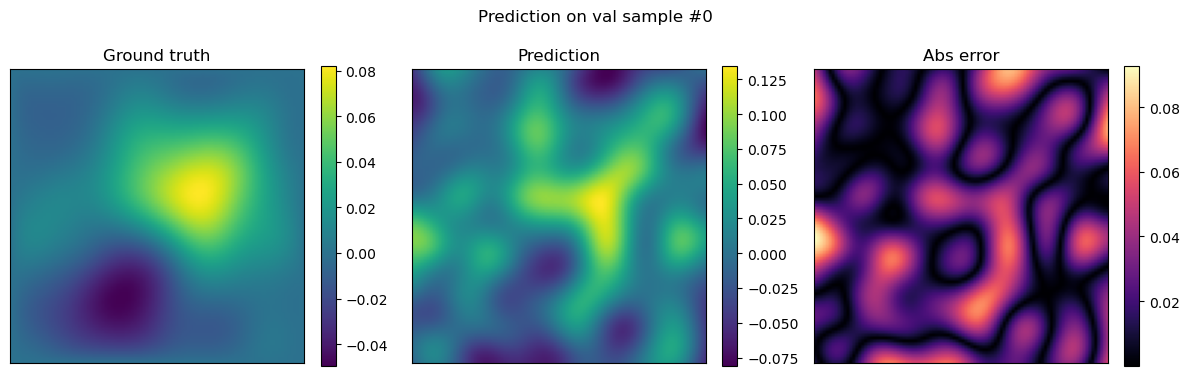

In [184]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# --- pick one sample from arrays X_val, Y_val ---
idx = 0  # choose which sample to visualize

# X_val: (B, C_in, N, N) or (B, N, N)
# Y_val: (B, 1, N, N)   or (B, N, N)
x_in  = X_val[idx]
y_true_arr = Y_val[idx]

# Ensure 3D field for y_true (N, N)
if y_true_arr.ndim == 3 and y_true_arr.shape[0] == 1:  # (1, N, N)
    y_true_2d = y_true_arr[0]
elif y_true_arr.ndim == 2:                             # (N, N)
    y_true_2d = y_true_arr
else:
    raise ValueError(f"Unexpected Y_val[idx] shape: {y_true_arr.shape}")

N = y_true_2d.shape[-1]

device = torch.device("cpu")
trained_model.to(device)
trained_model.eval()

# Build input tensor: (1, C_in, N, N)
if isinstance(x_in, np.ndarray):
    x_t = torch.from_numpy(x_in).to(dtype=torch.float32)
elif isinstance(x_in, torch.Tensor):
    x_t = x_in.detach().to(dtype=torch.float32)
else:
    raise TypeError("x_in must be numpy array or torch tensor")

# Add missing channel dim if needed: (N, N) -> (1, N, N)
if x_t.ndim == 2:
    x_t = x_t.unsqueeze(0)
# Add batch dim: (C_in, N, N) -> (1, C_in, N, N)
x_t = x_t.unsqueeze(0).to(device, non_blocking=True)

with torch.no_grad():
    y_pred_t = trained_model(x_t)            # expect (1, 1, N, N) or (1, N, N)
    # Squeeze batch/channel safely back to (N, N)
    if y_pred_t.ndim == 4 and y_pred_t.shape[1] == 1:
        y_pred_2d = y_pred_t[0, 0].cpu().numpy()
    elif y_pred_t.ndim == 3:
        y_pred_2d = y_pred_t[0].cpu().numpy()
    else:
        raise ValueError(f"Unexpected model output shape: {tuple(y_pred_t.shape)}")

y_true = y_true_2d  # already numpy (N, N)
y_pred = y_pred_2d  # numpy (N, N)


# --- plot ---
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

im0 = axs[0].imshow(y_true, origin="lower", cmap="viridis")
axs[0].set_title("Ground truth")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(y_pred, origin="lower", cmap="viridis")
axs[1].set_title("Prediction")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

im2 = axs[2].imshow(np.abs(y_pred - y_true), origin="lower", cmap="magma")
axs[2].set_title("Abs error")
plt.colorbar(im2, ax=axs[2], fraction=0.046)

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"Prediction on val sample #{idx}")
plt.tight_layout()
plt.show()
